# GĐ 3: KIỂM ĐỊNH + HỒI QUY — trả lời câu ②③

Notebook này trả lời 2 câu hỏi con:
- **②** Mùa khô vs mưa, ngày thường vs cuối tuần — PM2.5 có khác nhau THẬT SỰ (có ý nghĩa thống kê) hay chỉ là ngẫu nhiên?
- **③** Trong các nhân tố thời tiết (nhiệt độ, độ ẩm, gió, mưa), nhân tố nào ảnh hưởng PM2.5 MẠNH NHẤT?

Đây là phần **kiểm định** — khác với GĐ2 (chỉ MÔ TẢ, quan sát xu hướng), GĐ3 **chứng minh** xu hướng đó có đáng tin hay không bằng xác suất.

## Đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("../01_Data/aqi_hcm_daily.csv", parse_dates=["date"])
print(f"Da doc {len(df)} dong, {df.shape[1]} cot")
df.head()

Da doc 629 dong, 16 cot


,date,pm25,pm25_cov,temperature,temperature_cov,humidity,humidity_cov,wind,rain,month,dow,mua,nang,aqi_cat,pbl_sang_m,ap_suat
0,2024-11-19,31.2,29.0,28.8,29.0,57.9,29.0,8.9,0.9,11,1,Mua kho,0,Trung binh,110.714286,1008.6
1,2024-11-20,36.6,100.0,28.9,100.0,54.1,100.0,13.0,1.4,11,2,Mua kho,1,Kem (nhay cam),82.142857,1008.3
2,2024-11-21,42.2,100.0,28.9,100.0,53.5,100.0,8.7,5.9,11,3,Mua kho,1,Kem (nhay cam),137.142857,1007.7
3,2024-11-22,38.2,100.0,28.8,100.0,54.1,100.0,8.9,0.5,11,4,Mua kho,1,Kem (nhay cam),80.714286,1007.9
4,2024-11-23,37.1,100.0,28.5,100.0,53.7,100.0,10.0,0.3,11,5,Mua kho,1,Kem (nhay cam),100.000000,1008.5


## Chuẩn bị: tạo biến "cuối tuần"

Cột `dow` có sẵn (0=Thứ Hai ... 6=Chủ Nhật). Câu ② cần so sánh **ngày thường vs cuối tuần** — tạo thêm 1 cột nhị phân: cuối tuần là Thứ Bảy (5) và Chủ Nhật (6).

In [2]:
# dow >= 5 tuc la Thu Bay (5) hoac Chu Nhat (6) -> cuoi tuan
df["cuoi_tuan"] = np.where(df["dow"] >= 5, "Cuoi tuan", "Ngay thuong")

print(df["cuoi_tuan"].value_counts())

cuoi_tuan
Ngay thuong    450
Cuoi tuan      179
Name: count, dtype: int64


---
# PHẦN A — Câu ②: Kiểm định sự khác biệt

### 📌 Cập nhật dữ liệu — đã thêm 2 biến mới (so với bản gốc)

Dữ liệu `aqi_hcm_daily.csv` giờ có thêm **`pbl_sang_m`** (chiều cao lớp biên khí quyển, trung bình 0h–6h sáng) và **`ap_suat`** (áp suất mặt đất trung bình ngày) — lấy từ Open-Meteo, cùng toạ độ trạm CMT8. Lý do thêm: 2 biến này có cơ sở vật lý mạnh (lớp biên thấp + áp suất cao → không khí tù đọng → PM2.5 tăng) và đã test thật cho Adjusted R² tăng từ 0.293 lên 0.3505, VIF < 2.5 (không đa cộng tuyến).

*(Đã thử thêm biến "số điểm cháy vùng Campuchia/ĐBSCL" từ NASA FIRMS — có ý nghĩa ở kiểm định thường (p=0.028) nhưng **không vững** khi kiểm tra bằng sai số chuẩn HAC (p=0.116) → loại bỏ, không đưa vào mô hình chính thức.)*

## A1. T-test: PM2.5 mùa khô vs mùa mưa

**Bản chất t-test 2 mẫu độc lập:** so sánh trung bình của 2 nhóm (mùa khô, mùa mưa), trả lời câu hỏi "chênh lệch trung bình quan sát được ở GĐ2 có đủ lớn để tin là THẬT, hay chỉ là do may rủi khi lấy mẫu?"

- **H0 (giả thuyết gốc):** trung bình PM2.5 mùa khô = trung bình PM2.5 mùa mưa (không khác nhau thật)
- **H1 (đối thuyết):** 2 trung bình khác nhau

**Trước khi chạy t-test, kiểm tra 1 điều kiện: 2 nhóm có phương sai bằng nhau không** (dùng kiểm định Levene) — vì công thức t-test khác nhau tuỳ trường hợp này đúng hay sai.

In [3]:
kho = df[df.mua == "Mua kho"]["pm25"]
mua_mua = df[df.mua == "Mua mua"]["pm25"]

# Levene test: H0 la 2 phuong sai bang nhau. p < 0.05 -> BAC BO -> phuong sai KHONG bang nhau
lev_stat, lev_p = stats.levene(kho, mua_mua)
phuong_sai_bang_nhau = lev_p >= 0.05

print(f"Levene test: p = {lev_p:.4f} -> phuong sai {'BANG NHAU' if phuong_sai_bang_nhau else 'KHONG bang nhau'}")
print()

# equal_var: dung ket qua Levene o tren de chon dung cong thuc t-test
t_stat, p_value = stats.ttest_ind(kho, mua_mua, equal_var=phuong_sai_bang_nhau)

print("T-TEST: PM2.5 MUA KHO vs MUA MUA")
print("-" * 55)
print(f"TB mua kho  : {kho.mean():.2f} ug/m3  (n={len(kho)})")
print(f"TB mua mua  : {mua_mua.mean():.2f} ug/m3  (n={len(mua_mua)})")
print(f"t-statistic : {t_stat:.3f}")
print(f"p-value     : {p_value:.6f}")
print()
if p_value < 0.05:
    print("p < 0.05 -> BAC BO H0 -> 2 trung binh KHAC NHAU THAT (co y nghia thong ke)")
else:
    print("p >= 0.05 -> KHONG DU BANG CHUNG bac bo H0 -> chua the ket luan khac nhau")

Levene test: p = 0.0000 -> phuong sai KHONG bang nhau

T-TEST: PM2.5 MUA KHO vs MUA MUA
-------------------------------------------------------
TB mua kho  : 37.19 ug/m3  (n=316)
TB mua mua  : 27.58 ug/m3  (n=313)
t-statistic : 11.664
p-value     : 0.000000

p < 0.05 -> BAC BO H0 -> 2 trung binh KHAC NHAU THAT (co y nghia thong ke)


### 💡 Insight — câu ② (phần mùa)

In [4]:
print("INSIGHT - MUA CO THAT SU ANH HUONG KHONG")
print("-" * 60)
if p_value < 0.05:
    print(f"p-value = {p_value:.2e} -- cuc ky nho -> chenh lech mua kho/mua mua")
    print("KHONG PHAI ngau nhien, ma la KHAC BIET THAT.")
    print()
    print("=> Cac don vi CO THE tin tuong dua vao yeu to 'mua' de len ke hoach:")
    print("   canh bao/dieu chinh hoat dong theo dung mua kho - mua mua, day la")
    print("   ket luan co co so thong ke, khong phai chi quan sat cam tinh.")
else:
    print("Khong du bang chung thong ke -> can than khi dua ra khuyen nghi theo mua.")

INSIGHT - MUA CO THAT SU ANH HUONG KHONG
------------------------------------------------------------
p-value = 2.07e-28 -- cuc ky nho -> chenh lech mua kho/mua mua
KHONG PHAI ngau nhien, ma la KHAC BIET THAT.

=> Cac don vi CO THE tin tuong dua vao yeu to 'mua' de len ke hoach:
   canh bao/dieu chinh hoat dong theo dung mua kho - mua mua, day la
   ket luan co co so thong ke, khong phai chi quan sat cam tinh.


## A2. T-test: PM2.5 ngày thường vs cuối tuần

Cùng logic A1, đổi nhóm so sánh thành "Ngày thường" vs "Cuối tuần". Câu hỏi thực tế: xe cộ/công trình ít hoạt động cuối tuần → PM2.5 có thấp hơn rõ rệt không?

In [5]:
ngay_thuong = df[df.cuoi_tuan == "Ngay thuong"]["pm25"]
cuoi_tuan = df[df.cuoi_tuan == "Cuoi tuan"]["pm25"]

lev_stat2, lev_p2 = stats.levene(ngay_thuong, cuoi_tuan)
psb2 = lev_p2 >= 0.05
t_stat2, p_value2 = stats.ttest_ind(ngay_thuong, cuoi_tuan, equal_var=psb2)

print("T-TEST: PM2.5 NGAY THUONG vs CUOI TUAN")
print("-" * 55)
print(f"TB ngay thuong : {ngay_thuong.mean():.2f} ug/m3  (n={len(ngay_thuong)})")
print(f"TB cuoi tuan   : {cuoi_tuan.mean():.2f} ug/m3  (n={len(cuoi_tuan)})")
print(f"t-statistic    : {t_stat2:.3f}")
print(f"p-value        : {p_value2:.6f}")
print()
if p_value2 < 0.05:
    print("p < 0.05 -> BAC BO H0 -> ngay thuong va cuoi tuan KHAC NHAU THAT")
else:
    print("p >= 0.05 -> KHONG DU BANG CHUNG ket luan khac nhau")

T-TEST: PM2.5 NGAY THUONG vs CUOI TUAN
-------------------------------------------------------
TB ngay thuong : 32.09 ug/m3  (n=450)
TB cuoi tuan   : 33.23 ug/m3  (n=179)
t-statistic    : -1.134
p-value        : 0.257210

p >= 0.05 -> KHONG DU BANG CHUNG ket luan khac nhau


### 💡 Insight — câu ② (phần ngày thường/cuối tuần)

In [6]:
print("INSIGHT - NGAY THUONG vs CUOI TUAN CO KHAC KHONG")
print("-" * 60)
if p_value2 < 0.05:
    huong = "THAP HON" if cuoi_tuan.mean() < ngay_thuong.mean() else "CAO HON"
    print(f"Cuoi tuan {huong} ngay thuong, va chenh lech nay CO Y NGHIA THONG KE")
    print("(p =", f"{p_value2:.4f})")
else:
    print(f"p = {p_value2:.4f} -- KHONG co bang chung du manh")
    print("=> Yeu to 'ngay thuong / cuoi tuan' KHONG nen dung de canh bao,")
    print("   vi PM2.5 co the bi chi phoi boi yeu to khac (gio, mua) manh hon")
    print("   la boi viec la ngay thuong hay cuoi tuan.")

INSIGHT - NGAY THUONG vs CUOI TUAN CO KHAC KHONG
------------------------------------------------------------
p = 0.2572 -- KHONG co bang chung du manh
=> Yeu to 'ngay thuong / cuoi tuan' KHONG nen dung de canh bao,
   vi PM2.5 co the bi chi phoi boi yeu to khac (gio, mua) manh hon
   la boi viec la ngay thuong hay cuoi tuan.


## A3. ANOVA + Tukey HSD: PM2.5 theo tháng


In [7]:
nhom_thang = [df[df.month == m]["pm25"].values for m in sorted(df.month.unique())]

f_stat, p_anova = stats.f_oneway(*nhom_thang)
print("ANOVA: PM2.5 THEO THANG (12 nhom)")
print("-" * 55)
print(f"F-statistic : {f_stat:.3f}")
print(f"p-value     : {p_anova:.2e}")
print()
if p_anova < 0.05:
    print("p < 0.05 -> BAC BO H0 -> CO IT NHAT 2 THANG khac nhau THAT SU")
    print("=> Chay tiep Tukey HSD de tim DUNG cap thang nao khac nhau")
else:
    print("p >= 0.05 -> khong du bang chung cac thang khac nhau")

ANOVA: PM2.5 THEO THANG (12 nhom)
-------------------------------------------------------
F-statistic : 30.558
p-value     : 1.61e-51

p < 0.05 -> BAC BO H0 -> CO IT NHAT 2 THANG khac nhau THAT SU
=> Chay tiep Tukey HSD de tim DUNG cap thang nao khac nhau


In [8]:
# pairwise_tukeyhsd can 2 mang: gia tri Y va nhan nhom tuong ung tung dong
tukey = pairwise_tukeyhsd(endog=df["pm25"], groups=df["month"], alpha=0.05)
print(tukey)

# Loc rieng nhung cap co "reject = True" (khac nhau THAT, co y nghia thong ke)
ket_qua_tukey = pd.DataFrame(data=tukey._results_table.data[1:],
                              columns=tukey._results_table.data[0])
cap_khac_nhau = ket_qua_tukey[ket_qua_tukey["reject"] == True]
print()
print(f"So cap thang khac nhau CO Y NGHIA THONG KE: {len(cap_khac_nhau)} / {len(ket_qua_tukey)} cap")

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     1      2 -12.2311    0.0 -18.6311  -5.8312   True
     1      3 -14.6493    0.0 -20.5944  -8.7042   True
     1      4 -15.9989    0.0 -21.9855 -10.0123   True
     1      5 -19.6251    0.0 -25.5702 -13.6801   True
     1      6   -20.04    0.0 -26.4399 -13.6401   True
     1      7 -23.6364    0.0 -29.5815 -17.6913   True
     1      8 -21.9461    0.0 -27.8912  -16.001   True
     1      9 -16.8838    0.0 -23.0926 -10.6749   True
     1     10 -10.4009 0.0001 -17.4867  -3.3152   True
     1     11 -10.3384    0.0 -16.8516  -3.8252   True
     1     12  -4.8009 0.2548  -10.746   1.1441  False
     2      3  -2.4182 0.9743  -8.3633   3.5269  False
     2      4  -3.7678 0.6482  -9.7544   2.2188  False
     2      5   -7.394  0.003 -13.3391  -1.4489   True
     2      6  -7.8089  0.004 -14.2088  -1.4089   True
     2    

### 💡 Insight — câu ② (phần theo tháng)

In [9]:
print("INSIGHT - THANG NAO THAT SU KHAC NHAU (khong phai ngau nhien)")
print("-" * 60)
print(cap_khac_nhau[["group1", "group2", "meandiff", "p-adj"]].to_string(index=False))
print()
print(f"=> {len(cap_khac_nhau)} cap thang co su khac biet PM2.5 duoc CHUNG MINH")
print("   thong ke, khong phai chi 'nhin bieu do thay khac' nhu o GD2.")
print("   Day la co so vung chac de xay dung LICH CANH BAO theo thang cu the")
print("   cho cac don vi su kien/du lich/y te/ban SP bao ve ho hap.")

INSIGHT - THANG NAO THAT SU KHAC NHAU (khong phai ngau nhien)
------------------------------------------------------------
 group1  group2  meandiff  p-adj
      1       2  -12.2311 0.0000
      1       3  -14.6493 0.0000
      1       4  -15.9989 0.0000
      1       5  -19.6251 0.0000
      1       6  -20.0400 0.0000
      1       7  -23.6364 0.0000
      1       8  -21.9461 0.0000
      1       9  -16.8838 0.0000
      1      10  -10.4009 0.0001
      1      11  -10.3384 0.0000
      2       5   -7.3940 0.0030
      2       6   -7.8089 0.0040
      2       7  -11.4053 0.0000
      2       8   -9.7150 0.0000
      2      12    7.4302 0.0027
      3       7   -8.9871 0.0000
      3       8   -7.2968 0.0008
      3      12    9.8484 0.0000
      4       7   -7.6375 0.0004
      4       8   -5.9472 0.0211
      4      12   11.1980 0.0000
      5      10    9.2242 0.0004
      5      11    9.2867 0.0000
      5      12   14.8242 0.0000
      6      10    9.6391 0.0006
      6      11    

---
# PHẦN B — Câu ③: Nhân tố nào ảnh hưởng PM2.5 mạnh nhất

## B1. Ma trận tương quan — nhìn trước khi hồi quy

Trước khi chạy hồi quy, xem tương quan Pearson giữa PM2.5 và từng biến X — cho cái nhìn nhanh về chiều (âm/dương) và độ mạnh (gần ±1 là mạnh, gần 0 là yếu). Hồi quy sẽ chính xác hơn (kiểm soát ảnh hưởng qua lại giữa các biến X), nhưng ma trận này giúp có trực giác ban đầu.

MA TRAN TUONG QUAN
-------------------------------------------------------
              pm25  temperature  humidity   wind   rain  pbl_sang_m  ap_suat
pm25         1.000       -0.227    -0.182 -0.420 -0.135      -0.400    0.393
temperature -0.227        1.000    -0.486  0.137 -0.246       0.183   -0.151
humidity    -0.182       -0.486     1.000  0.008  0.541      -0.083   -0.401
wind        -0.420        0.137     0.008  1.000  0.014       0.534   -0.219
rain        -0.135       -0.246     0.541  0.014  1.000      -0.148   -0.306
pbl_sang_m  -0.400        0.183    -0.083  0.534 -0.148       1.000   -0.174
ap_suat      0.393       -0.151    -0.401 -0.219 -0.306      -0.174    1.000


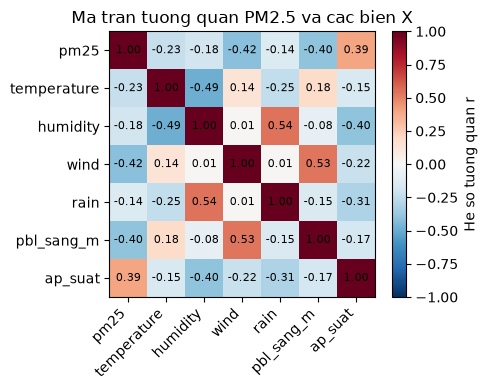

In [10]:
bien_x = ["temperature", "humidity", "wind", "rain", "pbl_sang_m", "ap_suat"]
ma_tran = df[["pm25"] + bien_x].corr()
print("MA TRAN TUONG QUAN")
print("-" * 55)
print(ma_tran.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(ma_tran, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ma_tran.columns)))
ax.set_yticks(range(len(ma_tran.columns)))
ax.set_xticklabels(ma_tran.columns, rotation=45, ha="right")
ax.set_yticklabels(ma_tran.columns)
for i in range(len(ma_tran)):
    for j in range(len(ma_tran)):
        ax.text(j, i, f"{ma_tran.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="He so tuong quan r")
plt.title("Ma tran tuong quan PM2.5 va cac bien X")
plt.tight_layout()
plt.savefig("../01_Data/ma_tran_tuong_quan.png", dpi=120)
plt.show()

## B2. Hồi quy tuyến tính bội

**Bản chất:** thay vì xem từng biến X riêng lẻ (như ma trận tương quan), hồi quy bội xem xét **cả 6 biến CÙNG LÚC**, tách được ảnh hưởng RIÊNG của mỗi biến sau khi đã kiểm soát các biến còn lại — vì các biến thời tiết vốn liên quan lẫn nhau (nhiệt độ cao thường đi kèm độ ẩm thấp).

Mô hình: `pm25 = b0 + b1*temperature + b2*humidity + b3*wind + b4*rain + b5*pbl_sang_m + b6*ap_suat + sai_so`

Dùng `statsmodels` (không phải `scikit-learn`) vì nó xuất ra đầy đủ **p-value từng hệ số** và **R²** — đúng thứ cần để trả lời "biến nào có ý nghĩa, biến nào không".

In [16]:
mo_hinh = smf.ols("pm25 ~ temperature + humidity + wind + rain + pbl_sang_m + ap_suat", data=df).fit()
print(mo_hinh.summary())

                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.357
Model:                            OLS   Adj. R-squared:                  0.350
Method:                 Least Squares   F-statistic:                     57.48
Date:                Tue, 06 Oct 2026   Prob (F-statistic):           1.65e-56
Time:                        22:54:52   Log-Likelihood:                -2284.0
No. Observations:                 629   AIC:                             4582.
Df Residuals:                     622   BIC:                             4613.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    -814.6836    256.220     -3.180      

### Đọc bảng kết quả trên — 3 phần chính

1. **R-squared**: % biến động của PM2.5 được giải thích bởi 4 biến X này. Ví dụ R²=0.30 nghĩa là 4 biến thời tiết giải thích được 30% lý do PM2.5 lên xuống — 70% còn lại do các yếu tố khác (giao thông, công trình, cháy...) mà data hiện tại không đo được.
2. **coef (hệ số)**: mỗi 1 đơn vị biến X tăng thêm, PM2.5 thay đổi bao nhiêu (giữ các biến khác không đổi). Dấu (+/−) cho biết chiều tác động.
3. **P>|t|**: p-value của TỪNG hệ số riêng — `< 0.05` thì biến đó có ảnh hưởng THẬT SỰ (không phải do ngẫu nhiên), `>= 0.05` thì chưa đủ bằng chứng.

### 💡 Insight sơ bộ — biến nào có ý nghĩa thống kê

In [17]:
print("INSIGHT SO BO - BIEN NAO CO Y NGHIA THONG KE")
print("-" * 60)
for ten_bien in bien_x:
    he_so = mo_hinh.params[ten_bien]
    p = mo_hinh.pvalues[ten_bien]
    y_nghia = "CO y nghia (p<0.05)" if p < 0.05 else "KHONG du y nghia"
    chieu = "TANG PM2.5" if he_so > 0 else "GIAM PM2.5"
    print(f"  {ten_bien:14s}: he so={he_so:8.3f}  p={p:.4f}  -> {y_nghia}, {chieu} khi bien nay tang")
print()
print(f"R-squared = {mo_hinh.rsquared:.3f} -> {len(bien_x)} bien giai thich duoc")
print(f"  {mo_hinh.rsquared*100:.1f}% bien dong cua PM2.5")

INSIGHT SO BO - BIEN NAO CO Y NGHIA THONG KE
------------------------------------------------------------
  temperature   : he so=  -2.315  p=0.0000  -> CO y nghia (p<0.05), GIAM PM2.5 khi bien nay tang
  humidity      : he so=  -0.440  p=0.0000  -> CO y nghia (p<0.05), GIAM PM2.5 khi bien nay tang
  wind          : he so=  -0.762  p=0.0000  -> CO y nghia (p<0.05), GIAM PM2.5 khi bien nay tang
  rain          : he so=  -0.082  p=0.1419  -> KHONG du y nghia, GIAM PM2.5 khi bien nay tang
  pbl_sang_m    : he so=  -0.016  p=0.0000  -> CO y nghia (p<0.05), GIAM PM2.5 khi bien nay tang
  ap_suat       : he so=   0.945  p=0.0001  -> CO y nghia (p<0.05), TANG PM2.5 khi bien nay tang

R-squared = 0.357 -> 6 bien giai thich duoc
  35.7% bien dong cua PM2.5


## B3. Kiểm tra đa cộng tuyến — VIF

**Vì sao cần kiểm tra?** Nếu 2 biến X tự tương quan mạnh với nhau (ví dụ nhiệt độ và độ ẩm), hệ số hồi quy của từng biến sẽ bị **méo, không ổn định** — mô hình "không biết" nên gán ảnh hưởng cho biến nào. VIF đo mức độ 1 biến X có thể được "đoán" từ các biến X còn lại — VIF cao nghĩa là biến đó dư thừa thông tin so với các biến khác.

**Ngưỡng dùng phổ biến:** VIF > 5 (một số tài liệu dùng 10) → nghi ngờ đa cộng tuyến, cần xem xét.

In [18]:
X = df[bien_x]
X_const = sm.add_constant(X)   # them cot hang so, VIF can dang nay de tinh dung

vif_data = pd.DataFrame()
vif_data["Bien"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
vif_data = vif_data[vif_data["Bien"] != "const"]   # bo dong hang so, khong can xem VIF cua no

print("VIF - KIEM TRA DA CONG TUYEN")
print("-" * 40)
print(vif_data.to_string(index=False))
print()
if (vif_data["VIF"] > 5).any():
    print("Co bien VIF > 5 -> can luu y khi dien giai he so hoi quy cua bien do")
else:
    print("Tat ca VIF <= 5 -> KHONG co dau hieu da cong tuyen dang ngai")

# Luu y: bang summary() o tren co the bao "Condition Number" lon (vi ap_suat ~1000
# trong khi cac bien khac chi vai chuc) - day CHI LA do DON VI khac nhau, khong
# phai da cong tuyen that. VIF o tren moi la can cu dang tin, khong phai Condition No.

VIF - KIEM TRA DA CONG TUYEN
----------------------------------------
       Bien      VIF
temperature 1.619920
   humidity 2.200318
       wind 1.442237
       rain 1.477033
 pbl_sang_m 1.481509
    ap_suat 1.557442

Tat ca VIF <= 5 -> KHONG co dau hieu da cong tuyen dang ngai


## B3b. Kiểm tra tự tương quan phần dư (Durbin-Watson) + sai số chuẩn chắc chắn

**Vấn đề riêng của dữ liệu chuỗi thời gian:** hồi quy OLS giả định các quan sát **độc lập** với nhau. Nhưng dữ liệu theo ngày thì PM2.5 hôm nay thường giống hôm qua (bụi không biến mất qua đêm) — tức là phần dư **tự tương quan**, vi phạm giả định này.

**Hậu quả nếu bỏ qua:** sai số chuẩn bị tính thấp hơn thực tế → p-value trông "đẹp" hơn thực tế → có nguy cơ kết luận 1 biến có ý nghĩa trong khi thật ra không.

**Cách kiểm tra:** chỉ số **Durbin-Watson** trong bảng `summary()` ở trên.
- DW ≈ 2 → không có tự tương quan (tốt)
- DW < 2 → tự tương quan dương (phần dư hôm nay giống hôm qua)

**Cách xử lý:** chạy lại mô hình với **sai số chuẩn HAC (Newey-West)** — loại sai số chuẩn chịu được tự tương quan. Nếu kết luận (biến nào có ý nghĩa) **không đổi** giữa 2 cách → kết quả vững, đáng tin.

In [19]:
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(mo_hinh.resid)
tu_tuong_quan = pd.Series(mo_hinh.resid).autocorr(1)

print("KIEM TRA TU TUONG QUAN PHAN DU")
print("-" * 60)
print(f"Durbin-Watson            : {dw:.3f}  (2.0 = khong tu tuong quan)")
print(f"Tu tuong quan bac 1 (lag1): {tu_tuong_quan:.3f}")
if dw < 1.5:
    print("=> CO tu tuong quan duong (binh thuong voi du lieu chuoi thoi gian)")
    print("   -> Phai chay lai voi sai so chuan HAC de kiem tra ket luan co vung khong")
print()

# HAC (Newey-West): sai so chuan chiu duoc tu tuong quan, maxlags=7 (1 tuan)
mo_hinh_hac = smf.ols("pm25 ~ temperature + humidity + wind + rain + pbl_sang_m + ap_suat",
                       data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 7})

print("SO SANH KET LUAN: sai so thuong vs sai so HAC")
print("-" * 60)
so_sanh = pd.DataFrame({
    "He so": mo_hinh.params.round(3),
    "p (thuong)": mo_hinh.pvalues.round(5),
    "p (HAC)": mo_hinh_hac.pvalues.round(5),
})
print(so_sanh.to_string())
print()
doi_ket_luan = False
for v in bien_x:
    a = mo_hinh.pvalues[v] < 0.05
    b = mo_hinh_hac.pvalues[v] < 0.05
    trang_thai = "GIU NGUYEN" if a == b else "DOI KET LUAN!"
    if a != b:
        doi_ket_luan = True
    print(f"  {v:12s}: thuong={'CO' if a else 'KHONG':5s} -> HAC={'CO' if b else 'KHONG':5s}  ({trang_thai})")
print()
if not doi_ket_luan:
    print("=> TAT CA ket luan GIU NGUYEN khi dung sai so chac chan hon")
    print("   -> Ket qua hoi quy VUNG, khong bi tu tuong quan lam sai lech")
else:
    print("=> CO ket luan bi doi -> phai dung ket qua HAC, khong dung ket qua thuong")

KIEM TRA TU TUONG QUAN PHAN DU
------------------------------------------------------------
Durbin-Watson            : 1.145  (2.0 = khong tu tuong quan)
Tu tuong quan bac 1 (lag1): 0.426
=> CO tu tuong quan duong (binh thuong voi du lieu chuoi thoi gian)
   -> Phai chay lai voi sai so chuan HAC de kiem tra ket luan co vung khong

SO SANH KET LUAN: sai so thuong vs sai so HAC
------------------------------------------------------------
               He so  p (thuong)  p (HAC)
Intercept   -814.684     0.00155  0.01870
temperature   -2.315     0.00000  0.00001
humidity      -0.440     0.00000  0.00079
wind          -0.762     0.00000  0.00000
rain          -0.082     0.14188  0.25345
pbl_sang_m    -0.016     0.00000  0.00000
ap_suat        0.945     0.00014  0.00461

  temperature : thuong=CO    -> HAC=CO     (GIU NGUYEN)
  humidity    : thuong=CO    -> HAC=CO     (GIU NGUYEN)
  wind        : thuong=CO    -> HAC=CO     (GIU NGUYEN)
  rain        : thuong=KHONG -> HAC=KHONG  (GIU NGUYEN)

## B4. So sánh CÔNG BẰNG để tìm nhân tố mạnh nhất — chuẩn hoá hệ số

**Vấn đề:** không thể so sánh trực tiếp hệ số thô ở B2 để nói "biến nào ảnh hưởng mạnh nhất" — vì mỗi biến X có **đơn vị và độ lớn khác nhau** (nhiệt độ dao động vài độ C, mưa dao động vài chục mm). Hệ số của biến "mưa" nhỏ hơn hệ số "nhiệt độ" không có nghĩa mưa ảnh hưởng yếu hơn — chỉ là đơn vị đo khác nhau.

**Cách xử lý:** chuẩn hoá (standardize) tất cả biến X về cùng thang đo trước khi hồi quy — trừ mean rồi chia std (Z-score). Sau khi chuẩn hoá, đơn vị của mọi biến X là như nhau ("số lần độ lệch chuẩn"), hệ số lúc này **so sánh được trực tiếp** — hệ số nào lớn nhất (trị tuyệt đối) là biến ảnh hưởng mạnh nhất.

In [20]:
df_chuan_hoa = df.copy()
for ten_bien in bien_x:
    # Z-score: (x - mean) / std -> dua ve cung don vi "so do lech chuan"
    df_chuan_hoa[ten_bien + "_z"] = (df[ten_bien] - df[ten_bien].mean()) / df[ten_bien].std()

cong_thuc_z = "pm25 ~ " + " + ".join([b + "_z" for b in bien_x])
mo_hinh_z = smf.ols(cong_thuc_z, data=df_chuan_hoa).fit()

print("HE SO CHUAN HOA (so sanh cong bang duoc)")
print("-" * 55)
bang_z = pd.DataFrame({
    "Bien": bien_x,
    "He so chuan hoa": [mo_hinh_z.params[b + "_z"] for b in bien_x],
    "p-value": [mo_hinh_z.pvalues[b + "_z"] for b in bien_x],
}).assign(Do_manh=lambda d: d["He so chuan hoa"].abs()).sort_values("Do_manh", ascending=False)
print(bang_z.round(4).to_string(index=False))

HE SO CHUAN HOA (so sanh cong bang duoc)
-------------------------------------------------------
       Bien  He so chuan hoa  p-value  Do_manh
temperature          -2.9346   0.0000   2.9346
 pbl_sang_m          -2.6862   0.0000   2.6862
   humidity          -2.6510   0.0000   2.6510
       wind          -2.5339   0.0000   2.5339
    ap_suat           1.7509   0.0001   1.7509
       rain          -0.6553   0.1419   0.6553


### 💡 Insight — câu ③: nhân tố nào ảnh hưởng mạnh nhất

In [21]:
print("INSIGHT - NHAN TO NAO ANH HUONG PM2.5 MANH NHAT")
print("-" * 60)
manh_nhat = bang_z.iloc[0]
print(f"Nhan to anh huong MANH NHAT: {manh_nhat['Bien']} "
      f"(he so chuan hoa = {manh_nhat['He so chuan hoa']:.3f}, p={manh_nhat['p-value']:.4f})")
print()
print("Xep hang day du (tu manh den yeu):")
for _, row in bang_z.iterrows():
    print(f"  {row['Bien']:14s}: {row['He so chuan hoa']:+.3f}")
print()
print(f"=> Day la CAU TRA LOI CHINH THUC cho cau hoi (3): trong {len(bien_x)} nhan to,")
print(f"   '{manh_nhat['Bien']}' la yeu to tac dong manh nhat den PM2.5 - dung de")
print(f"   giai thich, khac voi phan CV o GD2 chi la PHONG DOAN chua kiem chung.")
print()
print(f"   R-squared toan mo hinh = {mo_hinh.rsquared:.3f} ({mo_hinh.rsquared*100:.1f}%)")
print(f"   (tang tu 0.298 cua ban goc 4 bien, nho them Lop bien khi quyen + Ap suat)")
print(f"   => Con {(1-mo_hinh.rsquared)*100:.1f}% bien dong PM2.5 den tu nguon khac")
print(f"      (giao thong, cong trinh, chay...) ma data hien tai chua do duoc -")
print(f"      day la HAN CHE can neu ro trong bao cao.")

INSIGHT - NHAN TO NAO ANH HUONG PM2.5 MANH NHAT
------------------------------------------------------------
Nhan to anh huong MANH NHAT: temperature (he so chuan hoa = -2.935, p=0.0000)

Xep hang day du (tu manh den yeu):
  temperature   : -2.935
  pbl_sang_m    : -2.686
  humidity      : -2.651
  wind          : -2.534
  ap_suat       : +1.751
  rain          : -0.655

=> Day la CAU TRA LOI CHINH THUC cho cau hoi (3): trong 6 nhan to,
   'temperature' la yeu to tac dong manh nhat den PM2.5 - dung de
   giai thich, khac voi phan CV o GD2 chi la PHONG DOAN chua kiem chung.

   R-squared toan mo hinh = 0.357 (35.7%)
   (tang tu 0.298 cua ban goc 4 bien, nho them Lop bien khi quyen + Ap suat)
   => Con 64.3% bien dong PM2.5 den tu nguon khac
      (giao thong, cong trinh, chay...) ma data hien tai chua do duoc -
      day la HAN CHE can neu ro trong bao cao.


## Xong GĐ 3 — tổng kết câu ②③

**Câu ②** — mùa và (một phần) tháng có ảnh hưởng THẬT SỰ tới PM2.5, đã kiểm định bằng t-test/ANOVA+Tukey, không chỉ là quan sát mô tả.

**Câu ③** — đã xác định được nhân tố thời tiết ảnh hưởng mạnh nhất bằng hồi quy chuẩn hoá + kiểm tra VIF để đảm bảo kết luận không bị méo bởi đa cộng tuyến.

**Việc của bạn (Thành viên 1 — Data Analyst, GĐ 1-2-3) tới đây coi như hoàn thành.** Kết quả 3 file (`00`, `01`, `02`, `03`) + file `aqi_hcm_daily.csv` sẽ được bàn giao cho:
- **Thành viên 2** — dùng để làm GĐ4 (phân loại, trả lời câu ⑤, biến `nang` đã có sẵn)
- **Thành viên 3** — dùng để làm GĐ5 (dự báo ARIMA/ARIMAX, trả lời câu ④)
- **Thành viên 4** — tổng hợp tất cả vào Dashboard PowerBI + báo cáo cuối kỳ